# Post-Quantum Cryptography Migration Scanner: Phase 1 end-to-end run

Run all cells from top to bottom in the project root. Outputs go to `results/` and `report.md`.

In [1]:
# Install pinned dependencies once (uncomment if needed)
# !pip install -r requirements.txt

import os, sys
sys.path.insert(0, os.getcwd())

from src.pipeline import run_all

run = run_all()  # scanner + Processor A/B benchmark + public repos + report.md

[1/4] Scanner on labelled fixture corpus
[2/4] Phase 1 benchmark: Processor A vs Processor B (star GHZ, sizes 3 to 5)
[3/4] Public repositories: scan time, canary recall, review sheets
[4/4] Writing report.md
Done in 14.0s. See report.md and results/.


## Report

In [2]:
from IPython.display import Markdown, display

display(Markdown(open('report.md', encoding='utf-8').read()))

# Phase 1 Report: Cryptographic Inventory & Migration Scanner

_Generated 2026-10-13 10:49 by `python -m src.pipeline`. Every number here is produced by the code in `src/`._

## 1. Problem and domain

Domain: Post-Quantum Cryptography (Quantum-Safe Systems). The scanner flags quantum-vulnerable RSA, DSA, DH and ECC usage in Python source and maps each finding to NIST FIPS 203 (ML-KEM) or FIPS 204 (ML-DSA). The Phase 1 Processor A and B benchmark is reported in section 2.

## 2. Processor A vs Processor B benchmark

Circuit: star-shaped GHZ state (H on qubit 0, then CX from qubit 0 to every other qubit), measured in the computational basis. Exact reference: probability 1/2 each for the all-zeros and all-ones outcomes. Both processors use basis {rz, sx, x, cx}, optimization level 1, seed 42, 4096 shots, and identical synthetic noise (1q depolarizing 0.1%, 2q depolarizing 0.5%, readout 1%).

### 2.1 Headline comparison (5 logical qubits)

| processor | physical_qubits | depth_routed | depth_all_to_all | cx_routed | cx_all_to_all | cx_overhead | swap_est | p_success_ideal | p_success_noisy | hellinger_noisy |
|---|---|---|---|---|---|---|---|---|---|---|
| A | 5 | 9 | 8 | 7 | 4 | 3 | 1 | 1.000 | 0.932 | 0.932 |
| B | 9 | 8 | 8 | 4 | 4 | 0 | 0 | 1.000 | 0.940 | 0.940 |

Column definitions: `cx_overhead` is routed CX minus all-to-all CX; `swap_est` is `cx_overhead / 3`; `p_success` is the probability of the two GHZ outcomes.

### 2.2 Interpretation

Routing the 5-qubit star GHZ circuit needs 7 CX gates on Processor A (depth 9) and 4 on Processor B (depth 8).

Processor B adds fewer routing CX gates than Processor A (0 vs 3, roughly 0 vs 1 SWAPs), so its coupling map suits this circuit better.

Under identical synthetic noise, the GHZ success probability is 0.932 on A and 0.940 on B, against ideal values of 1.000 and 1.000. The drop from ideal to noisy comes from the two-qubit gates in each routed circuit, so the processor with fewer routed CX gates loses less fidelity.

### 2.3 Scaling across GHZ sizes

| processor | logical_qubits | depth_routed | cx_routed | cx_overhead | p_success_noisy | hellinger_noisy |
|---|---|---|---|---|---|---|
| A | 3 | 6 | 2 | 0 | 0.964 | 0.964 |
| A | 4 | 7 | 3 | 0 | 0.949 | 0.949 |
| A | 5 | 9 | 7 | 3 | 0.932 | 0.932 |
| B | 3 | 6 | 2 | 0 | 0.964 | 0.964 |
| B | 4 | 7 | 3 | 0 | 0.949 | 0.949 |
| B | 5 | 8 | 4 | 0 | 0.940 | 0.940 |

## 3. Cryptographic inventory scanner

### 3.1 Accuracy on the labelled fixture corpus

| files | lines | scan_time_s | tp | fp | fn | precision | recall | f1 |
|---|---|---|---|---|---|---|---|---|
| 9 | 146 | 0.007 | 13 | 0 | 1 | 1.000 | 0.929 | 0.963 |

Per family:

| family | tp | fp | fn | precision | recall | f1 |
|---|---|---|---|---|---|---|
| DH | 1 | 0 | 0 | 1.000 | 1.000 | 1.000 |
| DSA | 1 | 0 | 0 | 1.000 | 1.000 | 1.000 |
| ECC | 8 | 0 | 0 | 1.000 | 1.000 | 1.000 |
| RSA | 3 | 0 | 1 | 1.000 | 0.750 | 0.857 |

False negatives (1): `m1_wrapper_miss.py:5` (RSA). The known miss is a call through an internal wrapper library, which the scanner can't resolve without the library source.

False positives (0): none.

### 3.2 Migration plan

Each finding maps to a replacement: key establishment and encryption move to ML-KEM-768 (FIPS 203); signatures move to ML-DSA-65 (FIPS 204). Where usage can't be inferred, both are listed.

| family | usage | replacement | findings |
|---|---|---|---|
| DH | key_establishment | ML-KEM-768 (FIPS 203) | 1 |
| DSA | signature | ML-DSA-65 (FIPS 204) | 1 |
| ECC | key_establishment | ML-KEM-768 (FIPS 203) | 1 |
| ECC | signature | ML-DSA-65 (FIPS 204) | 4 |
| ECC | unknown | ML-KEM-768 (FIPS 203) if used for encryption or key exchange; ML-DSA-65 (FIPS 204) if used for signing | 3 |
| RSA | signature | ML-DSA-65 (FIPS 204) | 1 |
| RSA | unknown | ML-KEM-768 (FIPS 203) if used for encryption or key exchange; ML-DSA-65 (FIPS 204) if used for signing | 2 |

### 3.3 Public repositories

| repo | status | files | lines | scan_time_s | findings | canary_recall | precision | reviewed_findings |
|---|---|---|---|---|---|---|---|---|
| requests | scanned | 37 | 12069 | 0.112 | 0 | 0.929 |  | 0 |
| flask | scanned | 83 | 18416 | 0.231 | 0 | 0.929 |  | 0 |

`canary_recall` is measured by inserting known positive snippets into a copy of each repo. `precision` is computed from the manual review sheets in `data/processed/review_<repo>.csv`; it reads `pending` until those sheets are filled in (is_true_positive = 1 or 0).

## 4. Figures

![scanner_metrics](results/figures/scanner_metrics.png)

![coupling_map_processor_A](results/figures/coupling_map_processor_A.png)

![coupling_map_processor_B](results/figures/coupling_map_processor_B.png)

![scaling_depth_cx_success](results/figures/scaling_depth_cx_success.png)

![comparison_5q_bars](results/figures/comparison_5q_bars.png)

![repo_scan_time](results/figures/repo_scan_time.png)

## 5. Limitations

The labelled corpus is small and was written for this project, so its precision and recall are optimistic compared with a large, independently labelled set. The scanner only looks at Python, resolves calls through direct imports (not wrapper libraries), and guesses usage from names and nearby text, so some findings will be labelled `unknown`. The SWAP count is an estimate derived from CX overhead. Noise is the synthetic model from the problem specification, not a calibrated device model.

## 6. Reproduce

```
pip install -r requirements.txt
python -m src.pipeline
```
Or open `main.ipynb` and run all cells. All stochastic components use seed 42.


## Processor A vs Processor B: headline comparison (5 logical qubits)

In [3]:
import pandas as pd
pd.set_option('display.width', 200)
run['comparison_5q']

,processor,physical_qubits,logical_qubits,depth_routed,depth_all_to_all,cx_routed,cx_all_to_all,cx_overhead,swap_est,p_success_ideal,p_success_noisy,hellinger_ideal,hellinger_noisy
0,A,5,5,9,8,7,4,3,1,1.0,0.9321,0.9997,0.9320
1,B,9,5,8,8,4,4,0,0,1.0,0.9404,0.9997,0.9403


## Figures

results/figures\comparison_5q_bars.png


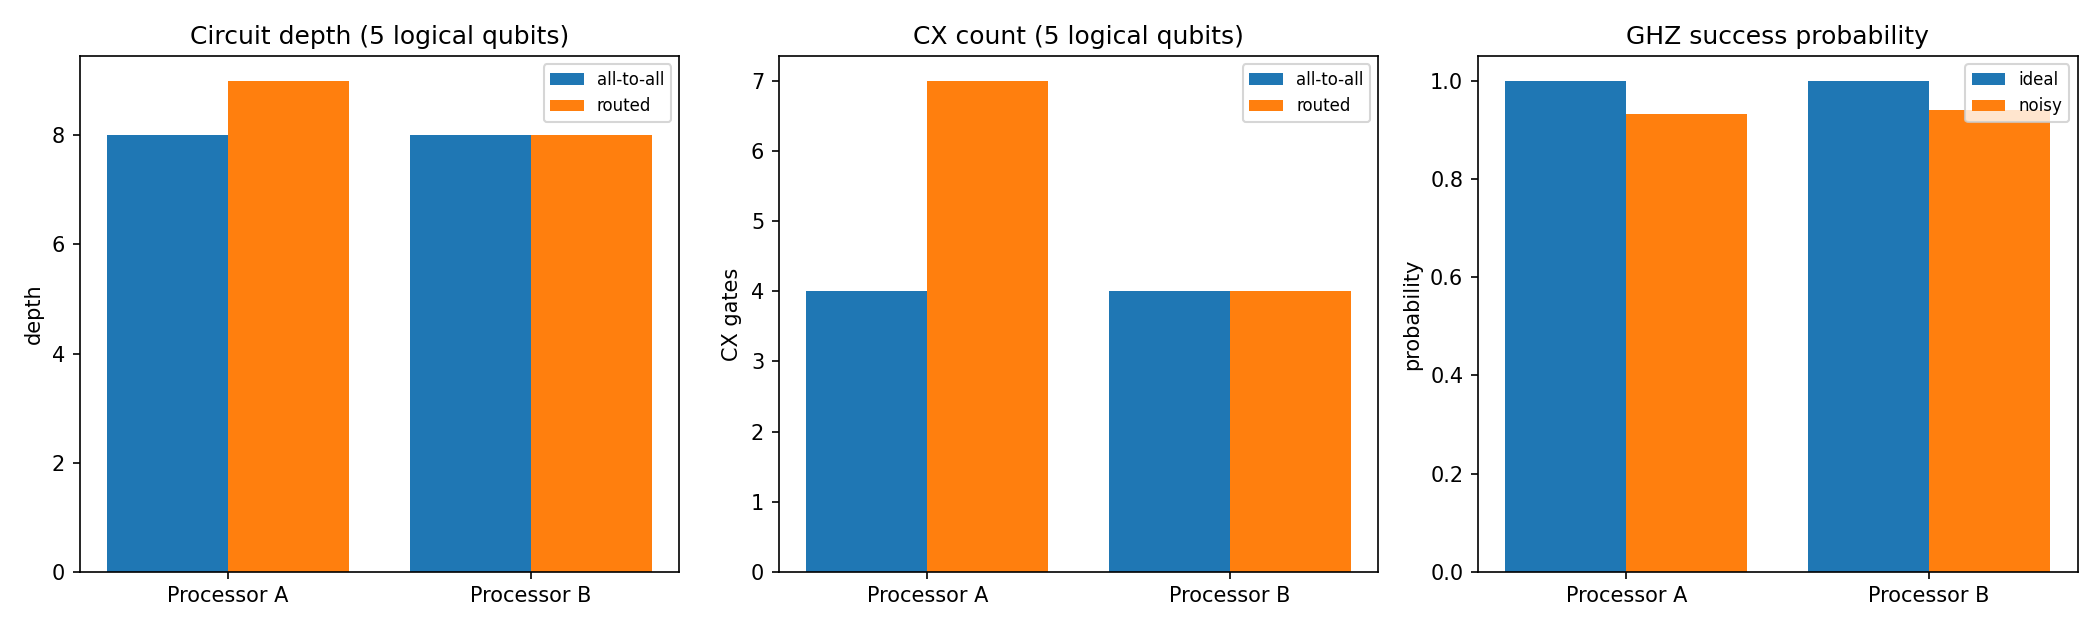

results/figures\coupling_map_processor_A.png


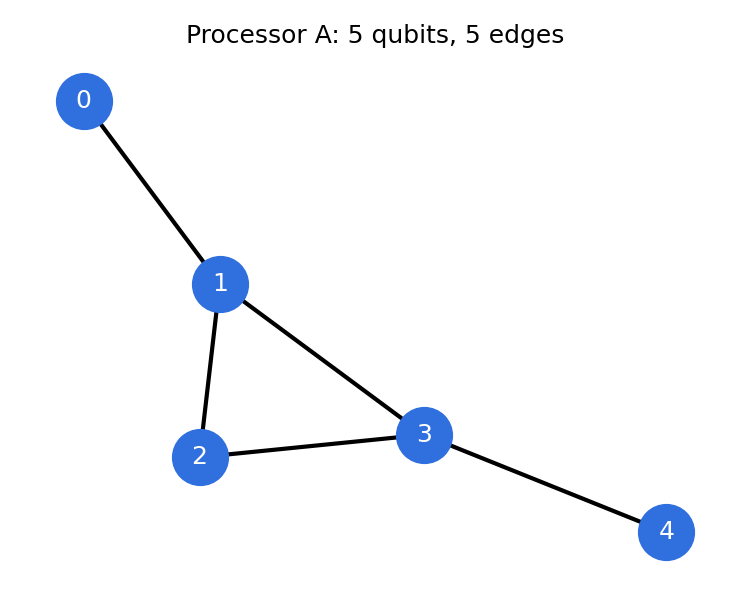

results/figures\coupling_map_processor_B.png


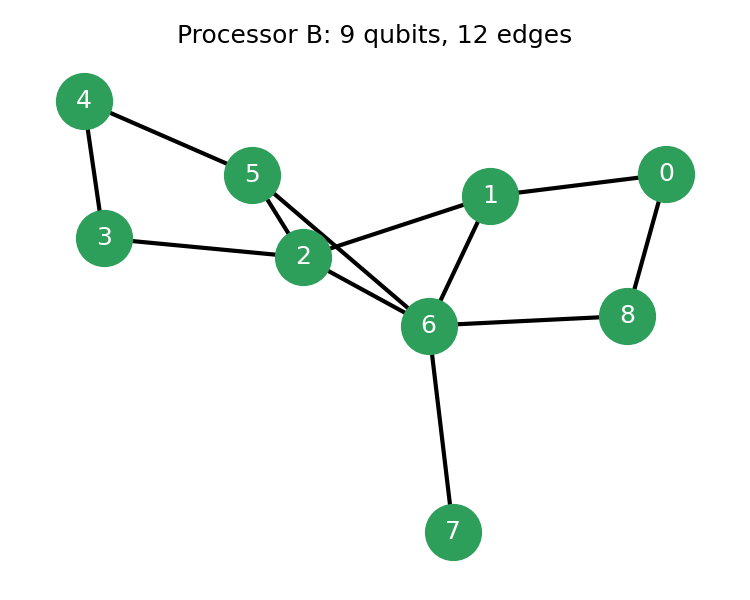

results/figures\repo_scan_time.png


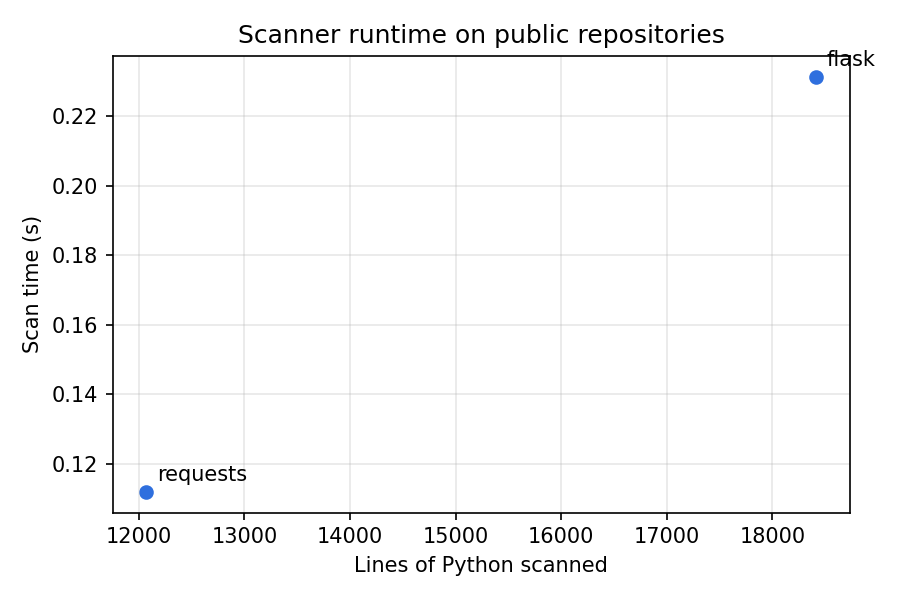

results/figures\scaling_depth_cx_success.png


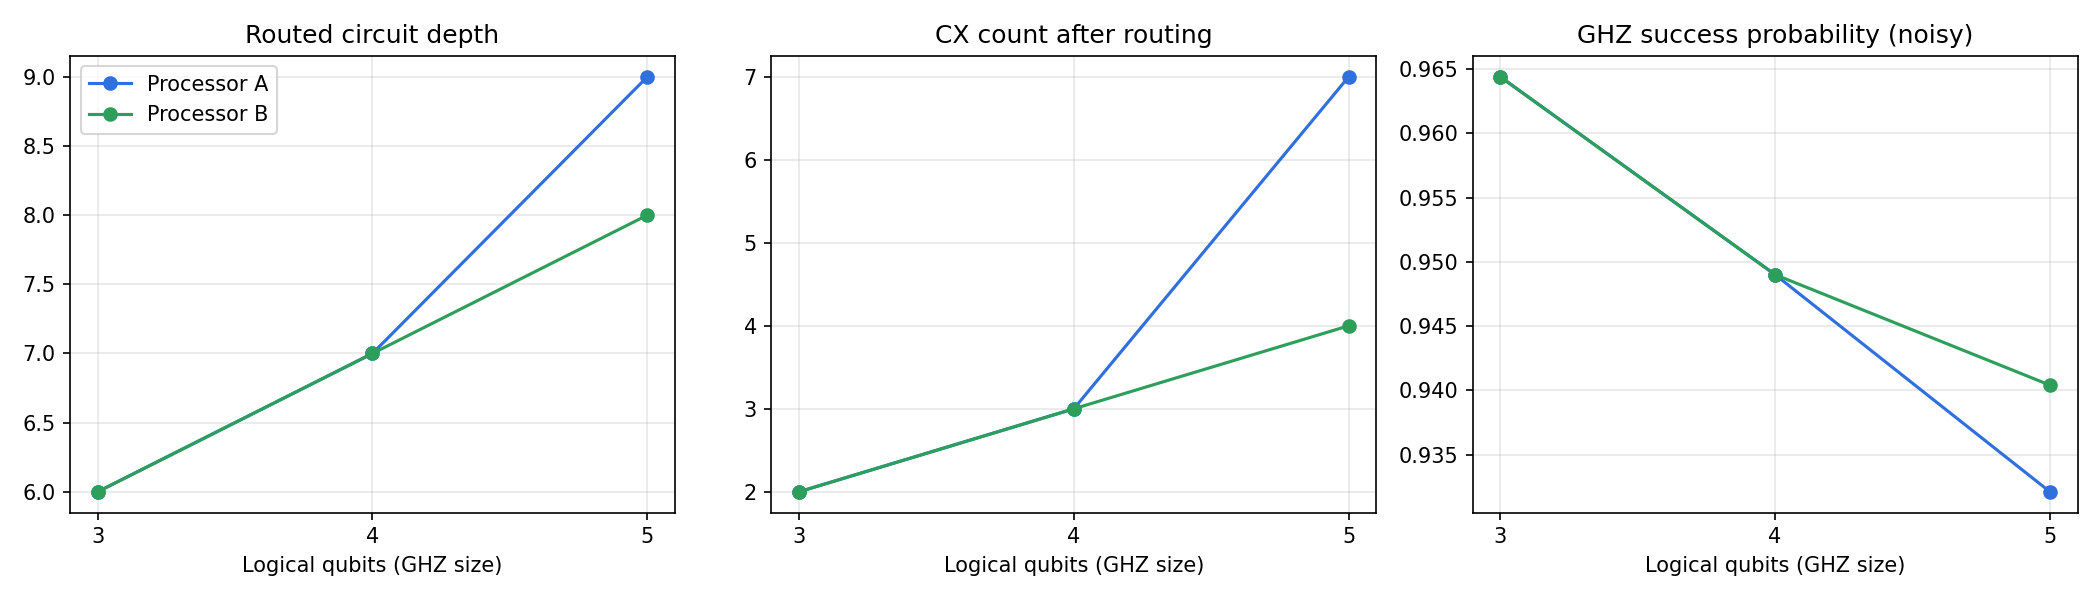

results/figures\scanner_metrics.png


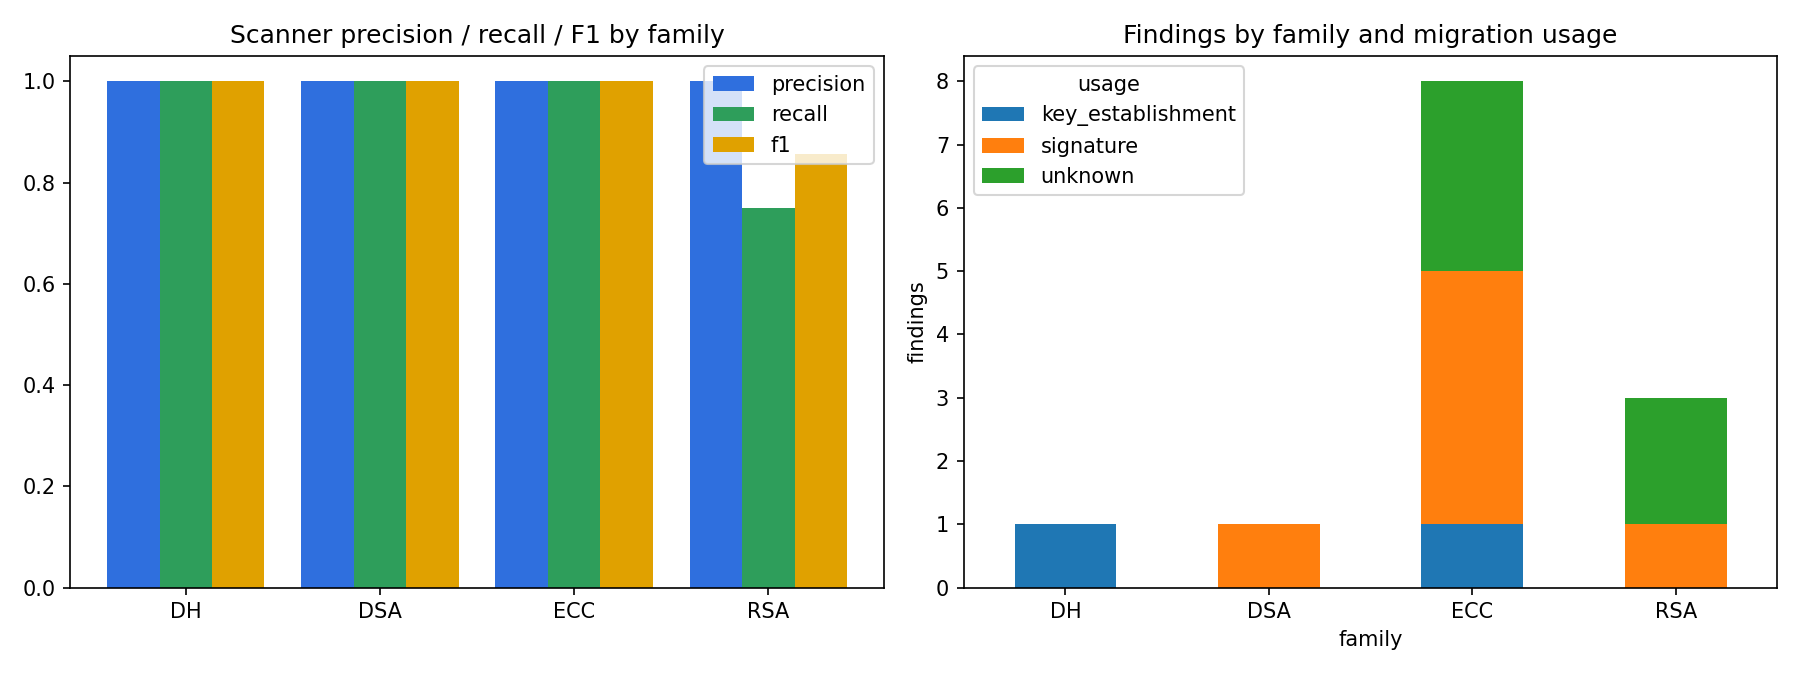

In [4]:
import glob
from IPython.display import Image, display

for path in sorted(glob.glob('results/figures/*.png')):
    print(path)
    display(Image(filename=path, width=750))

## Scanner on a single file or directory

The scanner also works on any folder. Each finding names the file, line, family, usage and the post-quantum replacement.

In [5]:
from dataclasses import asdict
from src.scanner import scan_path

report = scan_path('data/raw/ground_truth')
pd.DataFrame([asdict(f) for f in report.findings])

,file,line,family,matched,layer,usage,severity,replacement,snippet
0,a1_rsa_keygen.py,6,RSA,rsa.generate_private_key,ast,unknown,HIGH,ML-KEM-768 (FIPS 203) if used for encryption o...,key = rsa.generate_private_key(public_exponent...
1,a2_ecc_signing.py,7,ECC,ec.generate_private_key,ast,unknown,HIGH,ML-KEM-768 (FIPS 203) if used for encryption o...,return ec.generate_private_key(ec.SECP256R1())...
2,a2_ecc_signing.py,11,ECC,Ed25519PrivateKey.generate,ast,signature,HIGH,ML-DSA-65 (FIPS 204),key = Ed25519PrivateKey.generate() # EXPECT: ECC
3,a2_ecc_signing.py,16,ECC,ec.ECDSA,ast,signature,MEDIUM,ML-DSA-65 (FIPS 204),"return key.sign(payload, ec.ECDSA(hashes.SHA25..."
4,a3_dh_exchange.py,5,DH,dh.generate_parameters,ast,key_establishment,HIGH,ML-KEM-768 (FIPS 203),"params = dh.generate_parameters(generator=2, k..."
5,a3_dh_exchange.py,10,ECC,x25519.X25519PrivateKey.generate,ast,key_establishment,HIGH,ML-KEM-768 (FIPS 203),alice = x25519.X25519PrivateKey.generate() # ...
6,a4_dsa_and_pycryptodome.py,6,DSA,DSA.generate,ast,signature,HIGH,ML-DSA-65 (FIPS 204),return DSA.generate(2048) # EXPECT: DSA
7,a4_dsa_and_pycryptodome.py,10,RSA,RSA.import_key,ast,unknown,MEDIUM,ML-KEM-768 (FIPS 203) if used for encryption o...,return RSA.import_key(pem_text) # EXPECT: RSA
8,a5_jwt_algorithms.py,11,RSA,RS256,pattern,signature,MEDIUM,ML-DSA-65 (FIPS 204),"return jwt.encode(payload, private_pem, algori..."
9,a5_jwt_algorithms.py,15,ECC,ES256,pattern,signature,MEDIUM,ML-DSA-65 (FIPS 204),"return jwt.encode(payload, private_pem, algori..."


To scan a public repository, clone it first (`git clone --depth 1 https://github.com/psf/requests.git data/raw/repos/requests`) and call `scan_path('data/raw/repos/requests')`.